# 08 — Result figure: MAPE by model and horizon

Grouped-bar figure of the horizon-sweep results, rack **R0605-PA**, `lookback=60`,
`resample=30s`, full training data. **MAPE is the metric** because the project
targets are defined in MAPE (≤5 / 8 / 10 / 15 %).

**Direct multi-step forecasting for every bar except XGBoost at 1 day and 1 week**,
which is recursive single-step: direct multi-output XGBoost trains one tree per
output step (200 × horizon trees), impractical at H=2880 / 20160. The figure itself
is unmarked; the caption carries that note (see the last cell). Every number is
loaded from `results/`.

Written twice:
- `figures/paper/fig_mape_by_horizon.pdf` (+ `.png` preview) — 6.3 in, Computer Modern, for LaTeX
- `figures/slide/fig_mape_by_horizon.png` — 11 in, Calibri, 200 dpi, for slides

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

from rack_forecast.paths import RESULTS_ROOT
from rack_forecast.persistence import load_metrics

FIG_DIR = RESULTS_ROOT.parent / 'figures'   # results/ is gitignored; figures/ is not
print('figures ->', FIG_DIR)

figures -> D:\VinUni\code\NTU\figures


## 1. Result set

In [2]:
HORIZONS = ['15 min', '1 hour', '1 day', '1 week']
H_STEPS  = {'15 min': 30, '1 hour': 120, '1 day': 2880, '1 week': 20160}
TARGET   = {'15 min': 5, '1 hour': 8, '1 day': 10, '1 week': 15}
RUN_ID   = {'15 min': 'run_03', '1 hour': 'run_1h', '1 day': 'run_1d', '1 week': 'run_1w'}
MODELS   = ['linear', 'xgboost', 'lstm', 'cnn1d', 'transformer']
LABEL    = {'linear': 'Linear', 'xgboost': 'XGBoost', 'lstm': 'LSTM',
            'cnn1d': 'CNN1D', 'transformer': 'Transformer'}

# Direct multi-step everywhere, except XGBoost at the two long horizons (recursive).
RECURSIVE = {('1 day', 'xgboost'), ('1 week', 'xgboost')}

def run_folder(h, direct=True):
    base = f'{RUN_ID[h]}_R0605-PA_L60_H{H_STEPS[h]}'
    return RESULTS_ROOT / (f'{base}_multistep' if direct else base)

rows = []
for h in HORIZONS:
    for m in MODELS:
        direct = (h, m) not in RECURSIVE
        folder = run_folder(h, direct)
        rows.append({'horizon': h, 'model': m,
                     'strategy': 'direct' if direct else 'recursive',
                     'source': folder.name, **load_metrics(folder).loc[m].to_dict()})
res = pd.DataFrame(rows)

mape = (res.pivot(index='model', columns='horizon', values='MAPE(%)')
           .reindex(index=MODELS, columns=HORIZONS))
mape.round(2)

horizon,15 min,1 hour,1 day,1 week
model,,,,
linear,2.37,2.38,2.66,4.18
xgboost,2.34,2.35,2.73,2.73
lstm,2.36,2.38,2.59,2.58
cnn1d,2.44,2.51,3.22,3.01
transformer,3.00,2.94,2.98,3.04


In [3]:
best = res.loc[res.groupby('horizon')['MAPE(%)'].idxmin()].set_index('horizon').loc[HORIZONS]
pd.DataFrame({
    'target (%)': [TARGET[h] for h in HORIZONS],
    'best model': best['model'].map(LABEL),
    'MAPE (%)': best['MAPE(%)'].round(2),
    'R2': best['R2'].round(3),
    'meets target': best['MAPE(%)'] <= pd.Series(TARGET),
}, index=HORIZONS)

,target (%),best model,MAPE (%),R2,meets target
15 min,5,XGBoost,2.34,0.390,True
1 hour,8,XGBoost,2.35,0.383,True
1 day,10,LSTM,2.59,0.224,True
1 week,15,LSTM,2.58,0.233,True


## 2. Style

Okabe–Ito palette (colour-blind safe). `render()` draws the figure once per style
and saves it.

In [4]:
COLORS = {'linear': '#0072B2', 'xgboost': '#D55E00', 'lstm': '#009E73',
          'cnn1d': '#CC79A7', 'transformer': '#E69F00'}
NAVY = '#1F2A5C'

BASE_RC = {'axes.spines.top': False, 'axes.spines.right': False,
           'axes.grid': True, 'grid.alpha': 0.3, 'grid.linewidth': 0.6,
           'axes.edgecolor': '#444444', 'axes.axisbelow': True}

STYLES = {
    'paper': dict(width=6.3, exts=('pdf', 'png'), lw=1.4, rc={
        'font.family': 'serif', 'font.serif': ['cmr10'], 'mathtext.fontset': 'cm',
        'axes.formatter.use_mathtext': True, 'axes.unicode_minus': False,
        'font.size': 9, 'axes.labelsize': 9,
        'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 7.5}),
    'slide': dict(width=11.0, exts=('png',), lw=2.6, rc={
        'font.family': 'sans-serif', 'font.sans-serif': ['Calibri', 'Arial', 'DejaVu Sans'],
        'font.size': 15, 'axes.labelsize': 15,
        'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 12}),
}

def render(name, plot_fn, aspect, show='slide'):
    """Draw plot_fn(style_dict, figsize) once per style; save all; display one."""
    for style, s in STYLES.items():
        with mpl.rc_context({**BASE_RC, **s['rc']}):
            fig = plot_fn(s, (s['width'], s['width'] * aspect))
            for ext in s['exts']:
                out = FIG_DIR / style / f'{name}.{ext}'
                out.parent.mkdir(parents=True, exist_ok=True)
                fig.savefig(out, dpi=200, bbox_inches='tight')
            if style == show:
                display(fig)
            plt.close(fig)

def bold_num(text, s):
    """(label, fontweight) for an emphasised number. cmr10 has no bold weight,
    so the paper style uses mathtext bold instead."""
    if s['rc']['font.family'] == 'serif':
        return rf'$\mathbf{{{text}}}$', 'normal'
    return text, 'bold'

## 3. Figure — MAPE by model and horizon

Dashed line = target for that horizon; the best model per horizon is labelled.

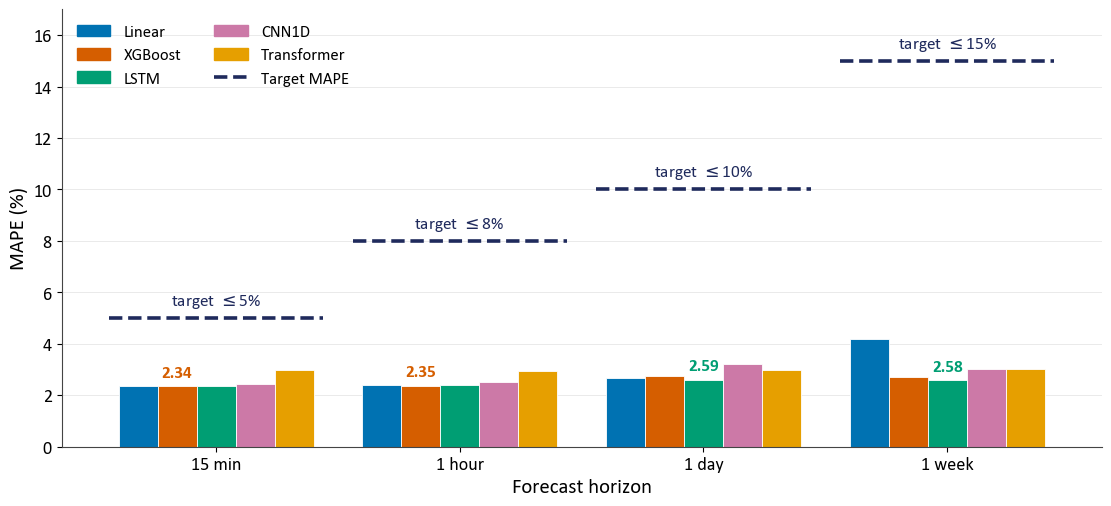

In [5]:
def fig_grouped_bars(s, figsize):
    fig, ax = plt.subplots(figsize=figsize, layout='constrained')
    w = 0.16
    for j, h in enumerate(HORIZONS):
        present = [m for m in MODELS if pd.notna(mape.loc[m, h])]
        offsets = (np.arange(len(present)) - (len(present) - 1) / 2) * w
        for off, m in zip(offsets, present):
            ax.bar(j + off, mape.loc[m, h], w, color=COLORS[m],
                   edgecolor='white', linewidth=0.6)
        ax.hlines(TARGET[h], j - 0.44, j + 0.44, color=NAVY, ls='--', lw=s['lw'])
        ax.text(j, TARGET[h] + 0.3, rf'target $\leq${TARGET[h]}%', ha='center',
                va='bottom', color=NAVY, fontsize='small')
        bm = mape[h].idxmin()
        txt, fw = bold_num(f'{mape.loc[bm, h]:.2f}', s)
        ax.text(j + offsets[present.index(bm)], mape.loc[bm, h] + 0.25, txt,
                ha='center', va='bottom', fontweight=fw, fontsize='small',
                color=COLORS[bm])
    ax.set_xticks(range(len(HORIZONS)), HORIZONS)
    ax.set_xlabel('Forecast horizon')
    ax.set_ylabel('MAPE (%)')
    ax.set_ylim(0, 17)
    ax.grid(axis='x', visible=False)
    handles = [mpl.patches.Patch(color=COLORS[m], label=LABEL[m]) for m in MODELS]
    handles.append(Line2D([], [], color=NAVY, ls='--', lw=s['lw'], label='Target MAPE'))
    ax.legend(handles=handles, loc='upper left', ncol=2, frameon=False)
    return fig

render('fig_mape_by_horizon', fig_grouped_bars, aspect=0.45)

## 4. Suggested LaTeX caption

```latex
\begin{figure}[htbp]
    \centering
    \includegraphics[width=\textwidth]{images/fig_mape_by_horizon.pdf}
    \caption{MAPE of each forecasting model at each horizon (rack R0605-PA).
    Dashed lines mark the project target; the best model per horizon is labelled.
    All results use direct multi-step forecasting except XGBoost at 1 day and
    1 week, which uses recursive single-step forecasting because direct
    multi-output XGBoost requires one tree per output step.}
    \label{fig:mape_by_horizon}
\end{figure}
```